<a href="https://colab.research.google.com/github/cmd0850/Chislovy_metodi/blob/main/%D0%9A%D0%BE%D0%BF%D1%96%D1%8F_%D0%B7%D0%B0%D0%BF%D0%B8%D1%81%D0%BD%D0%B8%D0%BA%D0%B0_%22%D0%9B%D0%A04_%D0%9C%D0%9D_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [2]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

path=kagglehub.dataset_download('hellbuoy/car-price-prediction')
df=pd.read_csv(os.path.join(path, 'CarPrice_Assignment.csv'))

display(df.head())

Using Colab cache for faster access to the 'car-price-prediction' dataset.


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [3]:
df.shape

(205, 26)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [5]:

df.dtypes

,0
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64


In [6]:
print('NAs',)
display(df.isna().sum().sort_values(ascending=False))

print('Duplicats', df.duplicated().sum()
)

print('Duplicated2:', df.drop(columns='car_ID').duplicated().sum())

NAs


,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


Duplicats 0
Duplicated2: 0


In [7]:
df['CarName'].value_counts()

,count
CarName,
peugeot 504,6
toyota corolla,6
toyota corona,6
subaru dl,4
mitsubishi outlander,3
...,...
volkswagen super beetle,1
volkswagen rabbit custom,1
volvo 245,1


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [9]:
ids=df['car_ID'].copy()

df_model=df.copy()
df_model['brand']=(
    df_model['CarName'].str.lower().str.split().str[0].replace({
        'maxda': 'mazda',
        'porcshe': 'porsche',
        'toyouta': 'toyota',
        'vokswagen': 'volkswagen',
        'vw': 'volkswagen'
    })
)

df_model=df_model.drop(columns=['car_ID', 'CarName'])

df_model

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0,volvo
201,-1,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,...,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0,volvo
202,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0,volvo
203,-1,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,...,idi,3.01,3.40,23.0,106,4800,26,27,22470.0,volvo


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


,skewness
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


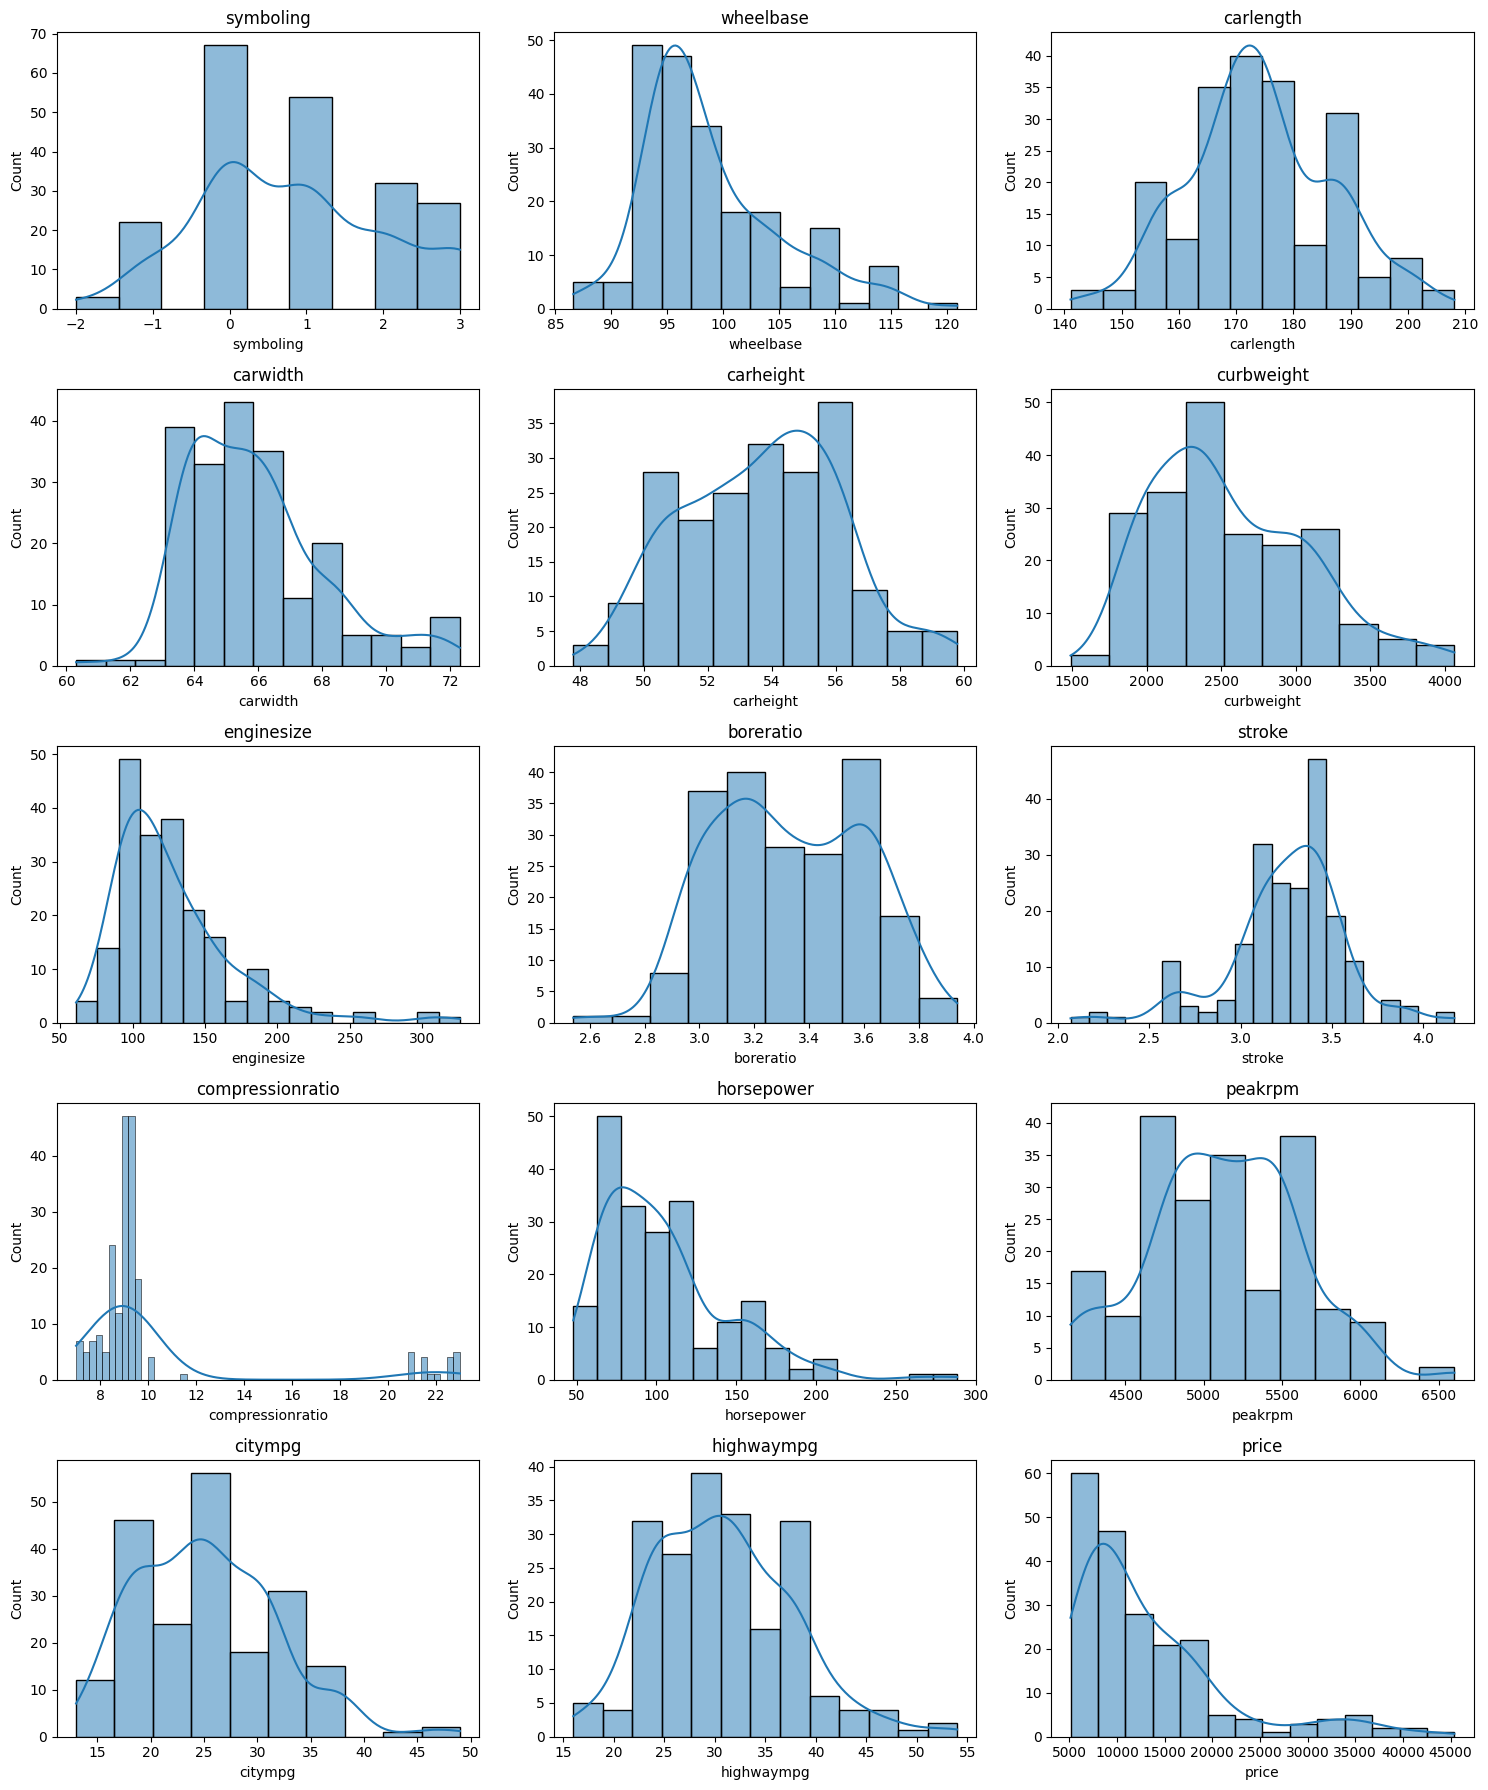

In [10]:
numeric_initial=df_model.select_dtypes(include=np.number).columns

skew_initial=df_model[numeric_initial].skew().sort_values(key=np.abs, ascending=False)

display(skew_initial.to_frame('skewness'))

ncols=3
nrows=int(np.ceil(len(numeric_initial)/ncols))
fig, axes=plt.subplots(nrows, ncols, figsize=(15, 3.6*nrows))
axes=np.array(axes).reshape(-1)
for ax, col in zip(axes, numeric_initial):
  sns.histplot(df_model[col], kde=True, ax=ax)
  ax.set_title(col)
for ax in axes[len(numeric_initial):]:
  ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [19]:
x=df_model.drop(columns='price')

y=df_model['price']

x_train, x_test, y_train, y_test=train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

id_train=ids.loc[x_train.index]
id_test=ids.loc[x_test.index]

print('train:', x_train.shape, 'test:', x_test.shape)

train: (164, 24) test: (41, 24)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [20]:
from pandas.tseries.offsets import QuarterBegin
con_cols=[
    c for c in x_train.select_dtypes(include=np.number).columns
    if c!='symboling'
    ]


q1=x_train[con_cols].quantile(0.25)
q3=x_train[con_cols].quantile(0.75)

iqr=q3-q1
lowBounds=q1-1.5*iqr

upBounds=q3+1.5*iqr

outlier=(
    (x_train[con_cols].lt(lowBounds)) |
    (x_train[con_cols].gt(upBounds))
).sum().sort_values(ascending=False)

display(outlier.to_frame('potential_outliners_train'))

x_train = x_train.copy()
x_test = x_test.copy()

x_train[con_cols] = x_train[con_cols].clip(lower=lowBounds, upper=upBounds, axis=1)
x_test[con_cols] = x_test[con_cols].clip(lower=lowBounds, upper=upBounds, axis=1)

,potential_outliners_train
compressionratio,20
stroke,16
carwidth,10
horsepower,7
enginesize,7
wheelbase,6
peakrpm,2
highwaympg,1
boreratio,1
curbweight,0


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


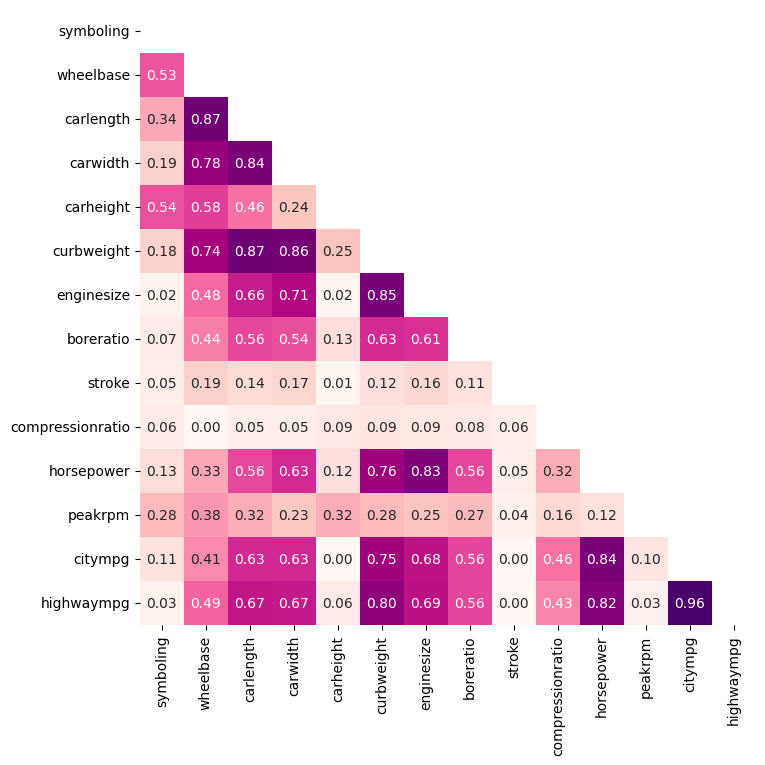

In [21]:
numerictraincols=x_train.select_dtypes(include=np.number).columns

corr=x_train[numerictraincols].corr().abs()

plt.figure(figsize=(10,8))

sns.heatmap(
     corr,
     cmap='RdPu',
     annot=True,
     fmt='.2f',
     mask=np.triu(np.ones_like(corr, dtype=bool)),
     square=True,
     cbar=False,
 )
plt.show()

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [23]:
con_cols=[
    c for c in x_train.select_dtypes(include=np.number).columns
    if c!='symboling'
]

ordinalnumericcols=[
    c for c in x_train.select_dtypes(include=np.number).columns
    if c=='symboling'
]

categorial_cols=(
    x_train.select_dtypes(exclude=np.number).columns.tolist()
)

numericpipeline=Pipeline(steps=[
    ('power', PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scaler', StandardScaler())
    ])

ordinal_pipeline=Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorial_pipeline=Pipeline(steps=[
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    )),
])

#об'єднуємо всі етапи
preprocessor=ColumnTransformer(
    transformers=[
        ('num', numericpipeline, con_cols),
        ('ord', ordinal_pipeline, ordinalnumericcols),
        ('cat', categorial_pipeline, categorial_cols)
    ]
)

x_train_prep=preprocessor.fit_transform(x_train)
x_test_prep=preprocessor.transform(x_test)

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [26]:
from scipy.stats import skew


skew_before=x_train[con_cols].apply(lambda s: skew(s, nan_policy='omit'))


fitted_num=preprocessor.named_transformers_['num']
x_train_num=pd.DataFrame(
    fitted_num.transform(x_train[con_cols]),
    columns=con_cols,
    index=x_train.index
)


skew_after=x_train_num.apply(lambda s: skew(s, nan_policy='omit'))

skew_compare=pd.DataFrame({
    'skew_before': skew_before,
    'skew_after': skew_after,
})
skew_compare['abs_before']=skew_compare['skew_before'].abs()
skew_compare['abs_after']=skew_compare['skew_after'].abs()
skew_compare['improved']=skew_compare['abs_after']<skew_compare['abs_before']

display(skew_compare.sort_values('abs_before', ascending=False).round(3))

print('Середня скев до:   ', skew_compare['abs_before'].mean().round(3))
print('Середня скев після:', skew_compare['abs_after'].mean().round(3))
print('Покращилось ознак:   ', skew_compare['improved'].sum(), 'з', len(con_cols))
print('Ознак з скев > 0.5 після:', (skew_compare['abs_after']>0.5).sum())

,skew_before,skew_after,abs_before,abs_after,improved
enginesize,0.954,0.044,0.954,0.044,True
wheelbase,0.927,0.020,0.927,0.020,True
horsepower,0.843,0.066,0.843,0.066,True
carwidth,0.724,0.269,0.724,0.269,True
curbweight,0.706,0.049,0.706,0.049,True
citympg,0.415,-0.008,0.415,0.008,True
stroke,-0.394,0.016,0.394,0.016,True
highwaympg,0.242,-0.012,0.242,0.012,True
carlength,0.235,0.003,0.235,0.003,True
boreratio,0.062,-0.006,0.062,0.006,True


Середня скев до:    0.433
Середня скев після: 0.039
Покращилось ознак:    13 з 13
Ознак з скев > 0.5 після: 0


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [27]:
models={
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0, random_state=42),
    'Lasso': Lasso(alpha=0.001, random_state=42, max_iter=10000),
    'RandomForest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR(kernel='rbf', C=1.0)
}

model_pipelines={
    name: Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('model', model)
    ])
    for name, model in models.items()
}

for name, pipe in model_pipelines.items():
    pipe.fit(x_train, y_train)
    print(f'{name} навчено')

LinearRegression навчено
Ridge навчено


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.881e+07, tolerance: 9.781e+05
  model = cd_fast.enet_coordinate_descent(


Lasso навчено
RandomForest навчено
GradientBoosting навчено
SVR навчено


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [28]:
results=[]

for name, pipe in model_pipelines.items():
    pipe.fit(x_train, y_train)
    pred=pipe.predict(x_test)

    results.append({
        'model': name,
        'R2': r2_score(y_test, pred),
        'MAE': mean_absolute_error(y_test, pred),
        'MSE': mean_squared_error(y_test, pred),
        'MAPE, %': mean_absolute_percentage_error(y_test, pred)*100
    })

results_df=(
    pd.DataFrame(results)
    .sort_values('R2', ascending=False)
    .reset_index(drop=True)
)

display(results_df.round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.881e+07, tolerance: 9.781e+05
  model = cd_fast.enet_coordinate_descent(


,model,R2,MAE,MSE,"MAPE, %"
0,RandomForest,0.960,1226.807,3.175518e+06,9.128
1,GradientBoosting,0.933,1660.138,5.254589e+06,11.138
2,LinearRegression,0.874,2133.535,9.968175e+06,16.050
3,Lasso,0.871,2199.520,1.018829e+07,17.331
4,Ridge,0.847,2376.548,1.210273e+07,18.957
5,SVR,-0.100,5695.319,8.680601e+07,36.012


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Логістік регрешн презначений для передбачень для дискретних ознак, тобто як марка авто наприклад. Бо вона генерує ймовірність належання до якогось класу. Ну і воно буде сприймати кожне значення ціни як окремий клас

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


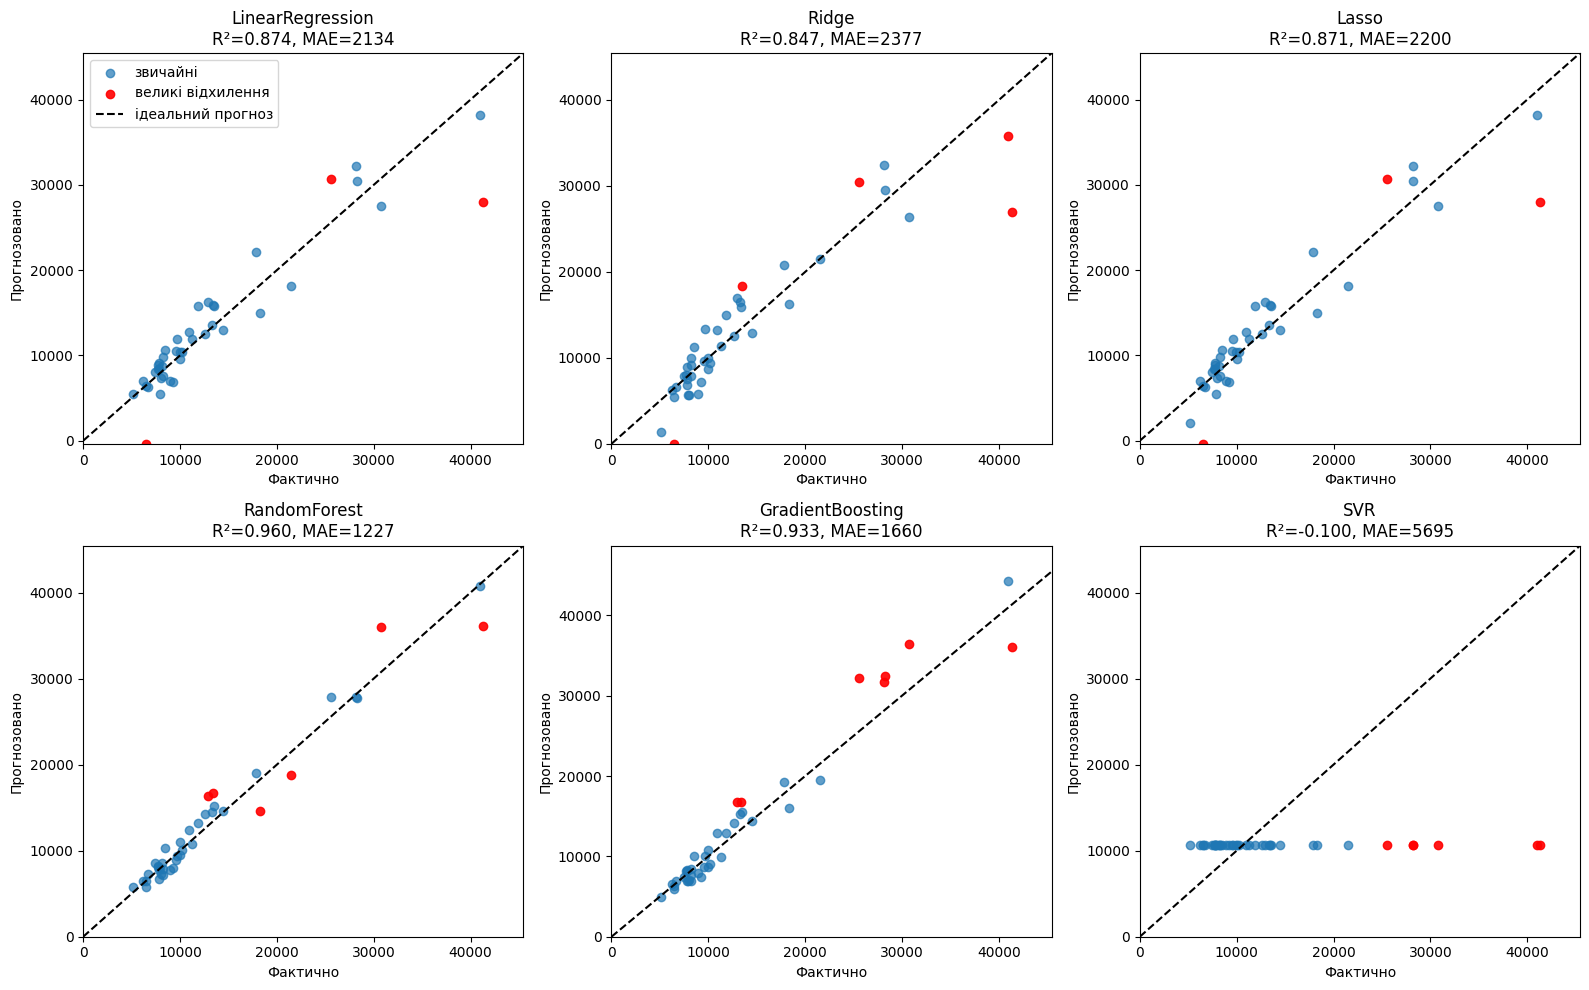


LinearRegression: великих відхилень 3


,actual,predicted,error
16,41315.0,27997.0,-13318.0
30,6479.0,-371.0,-6850.0
67,25552.0,30669.0,5117.0



Ridge: великих відхилень 5


,actual,predicted,error
16,41315.0,26951.0,-14364.0
30,6479.0,-44.0,-6523.0
73,40960.0,35798.0,-5162.0
67,25552.0,30426.0,4874.0
101,13499.0,18343.0,4844.0



Lasso: великих відхилень 3


...

,actual,predicted,error
15,30760.0,35991.0,5231.0
16,41315.0,36138.0,-5177.0
65,18280.0,14558.0,-3722.0
194,12940.0,16393.0,3453.0
195,13415.0,16737.0,3322.0



GradientBoosting: великих відхилень 7


,actual,predicted,error
67,25552.0,32161.0,6609.0
15,30760.0,36460.0,5700.0
16,41315.0,36023.0,-5292.0
68,28248.0,32448.0,4200.0
194,12940.0,16750.0,3810.0



SVR: великих відхилень 6


,actual,predicted,error
16,41315.0,10673.0,-30642.0
73,40960.0,10669.0,-30291.0
15,30760.0,10674.0,-20086.0
68,28248.0,10666.0,-17582.0
69,28176.0,10666.0,-17510.0


In [31]:
fig, axes=plt.subplots(2, 3, figsize=(16, 10))
axes=axes.ravel()

lim_min=min(y_test.min(), 0)
lim_max=y_test.max()*1.1

big_errors={}

for ax, (name, pipe) in zip(axes, model_pipelines.items()):
    pred=pipe.predict(x_test)
    abs_err=np.abs(y_test.values-pred)


    threshold=2*abs_err.mean()
    is_big=abs_err>threshold

    ax.scatter(y_test[~is_big], pred[~is_big], alpha=0.7, label='звичайні')
    ax.scatter(y_test[is_big], pred[is_big], color='red', alpha=0.9, label='великі відхилення')
    ax.plot([lim_min, lim_max], [lim_min, lim_max], 'k--', label='ідеальний прогноз')

    ax.set_xlim(lim_min, lim_max)
    ax.set_ylim(min(lim_min, pred.min()*1.1), max(lim_max, pred.max()*1.1))
    ax.set_title(f'{name}\nR²={r2_score(y_test, pred):.3f}, MAE={abs_err.mean():.0f}')
    ax.set_xlabel('Фактично')
    ax.set_ylabel('Прогнозовано')

    big_errors[name]=pd.DataFrame({
        'actual': y_test[is_big].values,
        'predicted': pred[is_big],
        'error': pred[is_big]-y_test[is_big].values
    }, index=y_test.index[is_big]).sort_values('error', key=np.abs, ascending=False)

axes[0].legend()
plt.tight_layout()
plt.show()

for name, df_err in big_errors.items():
    print(f'\n{name}: великих відхилень {len(df_err)}')
    display(df_err.head(5).round(0))

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [32]:
rf_pipe=model_pipelines['RandomForest']


sample_idx=x_test.sample(n=10, random_state=42).index

pred_sample=rf_pipe.predict(x_test.loc[sample_idx])

sample_table=pd.DataFrame({
    'car_ID': id_test.loc[sample_idx].values,
    'actual_price': y_test.loc[sample_idx].values,
    'predicted_price': pred_sample
}, index=sample_idx)

sample_table['abs_error']=(sample_table['actual_price']-sample_table['predicted_price']).abs()
sample_table['APE, %']=sample_table['abs_error']/sample_table['actual_price']*100

display(sample_table.reset_index(drop=True).round(2))

print('MAE на вибірці: ', sample_table['abs_error'].mean().round(2))
print('MAPE на вибірці:', sample_table['APE, %'].mean().round(2), '%')

,car_ID,actual_price,predicted_price,abs_error,"APE, %"
0,26,6692.0,7295.62,603.62,9.02
1,176,9988.0,10960.49,972.49,9.74
2,148,10198.0,10050.10,147.90,1.45
3,17,41315.0,36138.48,5176.52,12.53
4,69,28248.0,27753.21,494.79,1.75
5,147,7463.0,8517.86,1054.86,14.13
6,144,9960.0,9530.05,429.95,4.32
7,85,14489.0,14584.28,95.28,0.66
8,195,12940.0,16392.76,3452.76,26.68
9,160,7788.0,7737.35,50.65,0.65


MAE на вибірці:  1247.88
MAPE на вибірці: 8.09 %


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Найкраща якість була у рандом форест та градієнт бустінгу, бо їх максимальні похибки були у кілька разів менші - 5-6 тисяч проти 13, 30 тощо. Найбільші помилки припадають на рідкісні авто, бо ймовірно їх просто мало у навчальній виборці. передобробка більше всього допомагає лінійним моделям, а жддя дерев майже не впливає

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
